# 05 - Compare the four models, register them, write the report (`nhanes_v003b`)

This notebook **does not train anything and does not evaluate anything on the test set.** It loads only what notebooks 01-04 (and the 04b logistic-regression reference) saved: the metrics JSON files, their provenance blocks and the stored test-set predictions. It **fails loudly** if a model's JSON is missing, has no provenance, was written by a different notebook, or was built on a different frozen split (hash) than notebook 00's.

It then

1. checks provenance (notebook file, execution time, device, training time, library versions, split hash),
2. summarises the LightGBM early-stop diagnosis and the best-iteration check of the three boosted models,
3. builds the cross-model class-imbalance table (validation and test),
4. shows both operating points (`accuracy` = max sensitivity s.t. validation accuracy >= 72%, `balanced` = max balanced accuracy) on the held-out test cycle,
5. registers `*_nhanes_v003b` in `ml/models/registry_manifest.json` with status `pending_review` (**not deployed**; the earlier `nhanes_v003` entries and the active model are untouched), and
6. writes `ml/outputs/reports/nhanes_v003_report.md`.

**How to read the numbers.** About 90% of participants report no stone, so predicting "no stone" for everyone already scores about 90% accuracy ("majority baseline"). Accuracy above 70% is therefore easy to reach and is obtained **at the cost of sensitivity**; ROC-AUC and balanced accuracy are the honest yardsticks and are not expected to exceed 70%. All test metrics are on the held-out 2017-2018 cycle with 1,000-sample bootstrap 95% CIs and describe model performance on that population, not any individual patient.

## 1. Setup and load the saved results (with fail-loud checks)

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "ml" / "training" / "nhanes_common.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

from ml.training import nhanes_common as nc

nc.set_seeds()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("repo root:", ROOT.name)
print("dry run (test cycle untouched, outputs in ml/outputs/_dryrun):", nc.is_dry_run())

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

NOTEBOOK_FILE = "05_compare_and_register.ipynb"
MODELS = ["ebm", "catboost", "xgboost", "lightgbm"]
ALL = MODELS + ["logreg"]
NB_OF = {"ebm": "01_ebm.ipynb", "catboost": "02_catboost.ipynb", "xgboost": "03_xgboost.ipynb",
         "lightgbm": "04_lightgbm.ipynb", "logreg": "04b_logistic_regression_baseline.ipynb"}
LABEL = {"ebm": "EBM", "catboost": "CatBoost", "xgboost": "XGBoost", "lightgbm": "LightGBM", "logreg": "Logistic regression (reference)"}
COLOR = {"ebm": "#1f7a8c", "catboost": "#e07a1f", "xgboost": "#6a4c93", "lightgbm": "#3b8b3b", "logreg": "#777777"}

data_sum = nc.load_json(nc.metrics_dir() / "data_and_splits.json")
cfg = nc.load_feature_config()
PRIMARY = cfg["primary_variant"]
SPLIT_HASH = data_sum["split_manifest"]["hash"]

res = {}
for k in ALL:                                   # load ONLY saved artifacts; fail loudly on anything unexpected
    path = nc.metrics_dir() / f"{k}.json"
    if not path.exists():
        raise FileNotFoundError(f"{path.name} is missing - execute {NB_OF[k]} first (this notebook never retrains)")
    r = nc.load_json(path)
    prov = r.get("provenance")
    if not prov:
        raise RuntimeError(f"{path.name} has no provenance block - it was not written by the nhanes_v003b notebooks")
    if prov["notebook"] != NB_OF[k]:
        raise RuntimeError(f"{path.name} was written by {prov['notebook']}, expected {NB_OF[k]}")
    if prov["split_hash"] != SPLIT_HASH or r["split_hash"] != SPLIT_HASH:
        raise RuntimeError(f"{k}: split hash {prov['split_hash'][:12]} differs from notebook 00's {SPLIT_HASH[:12]} - re-run the notebooks in order")
    if r["model_name"] != f"{k}_{nc.RUN_TAG}":
        raise RuntimeError(f"{k}: model name {r['model_name']} is not {k}_{nc.RUN_TAG}")
    if r["dry_run"] != nc.is_dry_run() or r["primary_variant"] != PRIMARY:
        raise RuntimeError(f"{k}: dry-run flag / registered variant do not match this run")
    res[k] = r
print("All five metrics files carry provenance and used split hash", SPLIT_HASH[:16], "| registered variant:", PRIMARY, "| dry run:", nc.is_dry_run())

repo root: StoneSense-AI
dry run (test cycle untouched, outputs in ml/outputs/_dryrun): False
All five metrics files carry provenance and used split hash a2c3bdb15ffb9f3b | registered variant: base_history_sensitive | dry run: False


## 2. Provenance, data and cohort checks

In [2]:
prov_rows = []
for k in ALL:
    p = res[k]["provenance"]
    prov_rows.append({"model": LABEL[k], "notebook": p["notebook"], "executed_at (UTC)": p["executed_at"], "device": p["device"]["actual"],
                      "training s": p["training_seconds"], "notebook s": p["notebook_seconds"], "split hash": p["split_hash"][:12]})
prov_table = pd.DataFrame(prov_rows).set_index("model")
print(prov_table.to_string())
print("\nlibrary versions (identical across notebooks:", len({json.dumps(res[k]["provenance"]["libraries"], sort_keys=True) for k in ALL}) == 1, ")")
print(json.dumps(res["lightgbm"]["provenance"]["libraries"]))
display(pd.DataFrame(data_sum["cohort_check"]))
display(pd.DataFrame(data_sum["split_summary"]).set_index("split"))
print("History features used:", cfg["history_features_used"], "| excluded:", cfg["history_excluded"])
print("Validation cycle halves (same for every model): early-stopping half n =", res["lightgbm"]["validation_halves"]["early_stopping_n"],
      "| calibration/threshold half n =", res["lightgbm"]["validation_halves"]["calibration_n"], "| hash", res["lightgbm"]["validation_halves"]["hash"][:12])

                                                               notebook     executed_at (UTC)  device  training s  notebook s    split hash
model                                                                                                                                      
EBM                                                        01_ebm.ipynb  2026-10-15T08:35:14Z     cpu      291.37      316.45  a2c3bdb15ffb
CatBoost                                              02_catboost.ipynb  2026-10-15T08:42:06Z     GPU      380.28      407.40  a2c3bdb15ffb
XGBoost                                                03_xgboost.ipynb  2026-10-15T08:44:07Z  cuda:0       81.62      108.16  a2c3bdb15ffb
LightGBM                                              04_lightgbm.ipynb  2026-10-15T08:46:54Z     cpu      115.39      161.96  a2c3bdb15ffb
Logistic regression (reference)  04b_logistic_regression_baseline.ipynb  2026-10-15T08:47:32Z     cpu        8.02       33.21  a2c3bdb15ffb

library versions (i

,cycle,raw_rows,raw_usable_answer_rows,raw_yes,cohort_rows,cohort_positives,rows_match,positives_match
0,2007-2008,5935,5909,539,5909,539,True,True
1,2009-2010,6218,6201,542,6201,542,True,True
2,2011-2012,5560,5548,458,5548,458,True,True
3,2013-2014,5769,5758,535,5758,535,True,True
4,2015-2016,5719,5705,606,5705,606,True,True
5,2017-2018,5569,5558,554,5558,554,True,True


,cycles,rows,positives,positive_rate_pct
split,,,,
train,"2007-2008, 2009-2010, 2011-2012, 2013-2014",23416,2074,8.86
validation,2015-2016,5705,606,10.62
test,2017-2018,5558,554,9.97


History features used: ['BPQ020', 'BPQ080', 'DIQ010', 'MCQ080'] | excluded: {'MCQ520': 'not collected in cycle(s) 2007-2008, 2009-2010, 2011-2012, 2013-2014, 2015-2016', 'MCQ550': 'not collected in cycle(s) 2007-2008, 2009-2010, 2011-2012, 2013-2014, 2015-2016'}
Validation cycle halves (same for every model): early-stopping half n = 2852 | calibration/threshold half n = 2853 | hash 06045bb720e5


## 3. LightGBM early stop: before / after, and the best-iteration check of all three boosted models

LightGBM boosting rounds (registered variant)
  nhanes_v003 (before): best_iteration_ = 3
  old setup replicated in notebook 04: best_iteration_ = 3, rounds trained = 153, stopped by: binary_logloss
  nhanes_v003b (after): best_iteration_ = 190, rounds trained = 390

verdict on the suspected causes (computed in notebook 04):
  TRUE : (a) early stopping used another metric (logloss) instead of AUC
  TRUE : (b) scale_pos_weight inflates probabilities, so UNWEIGHTED validation logloss rises at once
  false: (c) learning rate / leaves too loose (old params reach their logloss minimum much sooner than the new defaults, even unweighted)
  false: (d) validation cycle differs from the training cycles (logloss minimum comes earlier there than on a random train hold-out)
  false: (e) stopping_rounds too small (patience 200 would not stop at the same place as 150)
  TRUE : (f) same validation rows used for early stopping AND calibration / thresholds

best_iteration_ of all three boosted models:
 

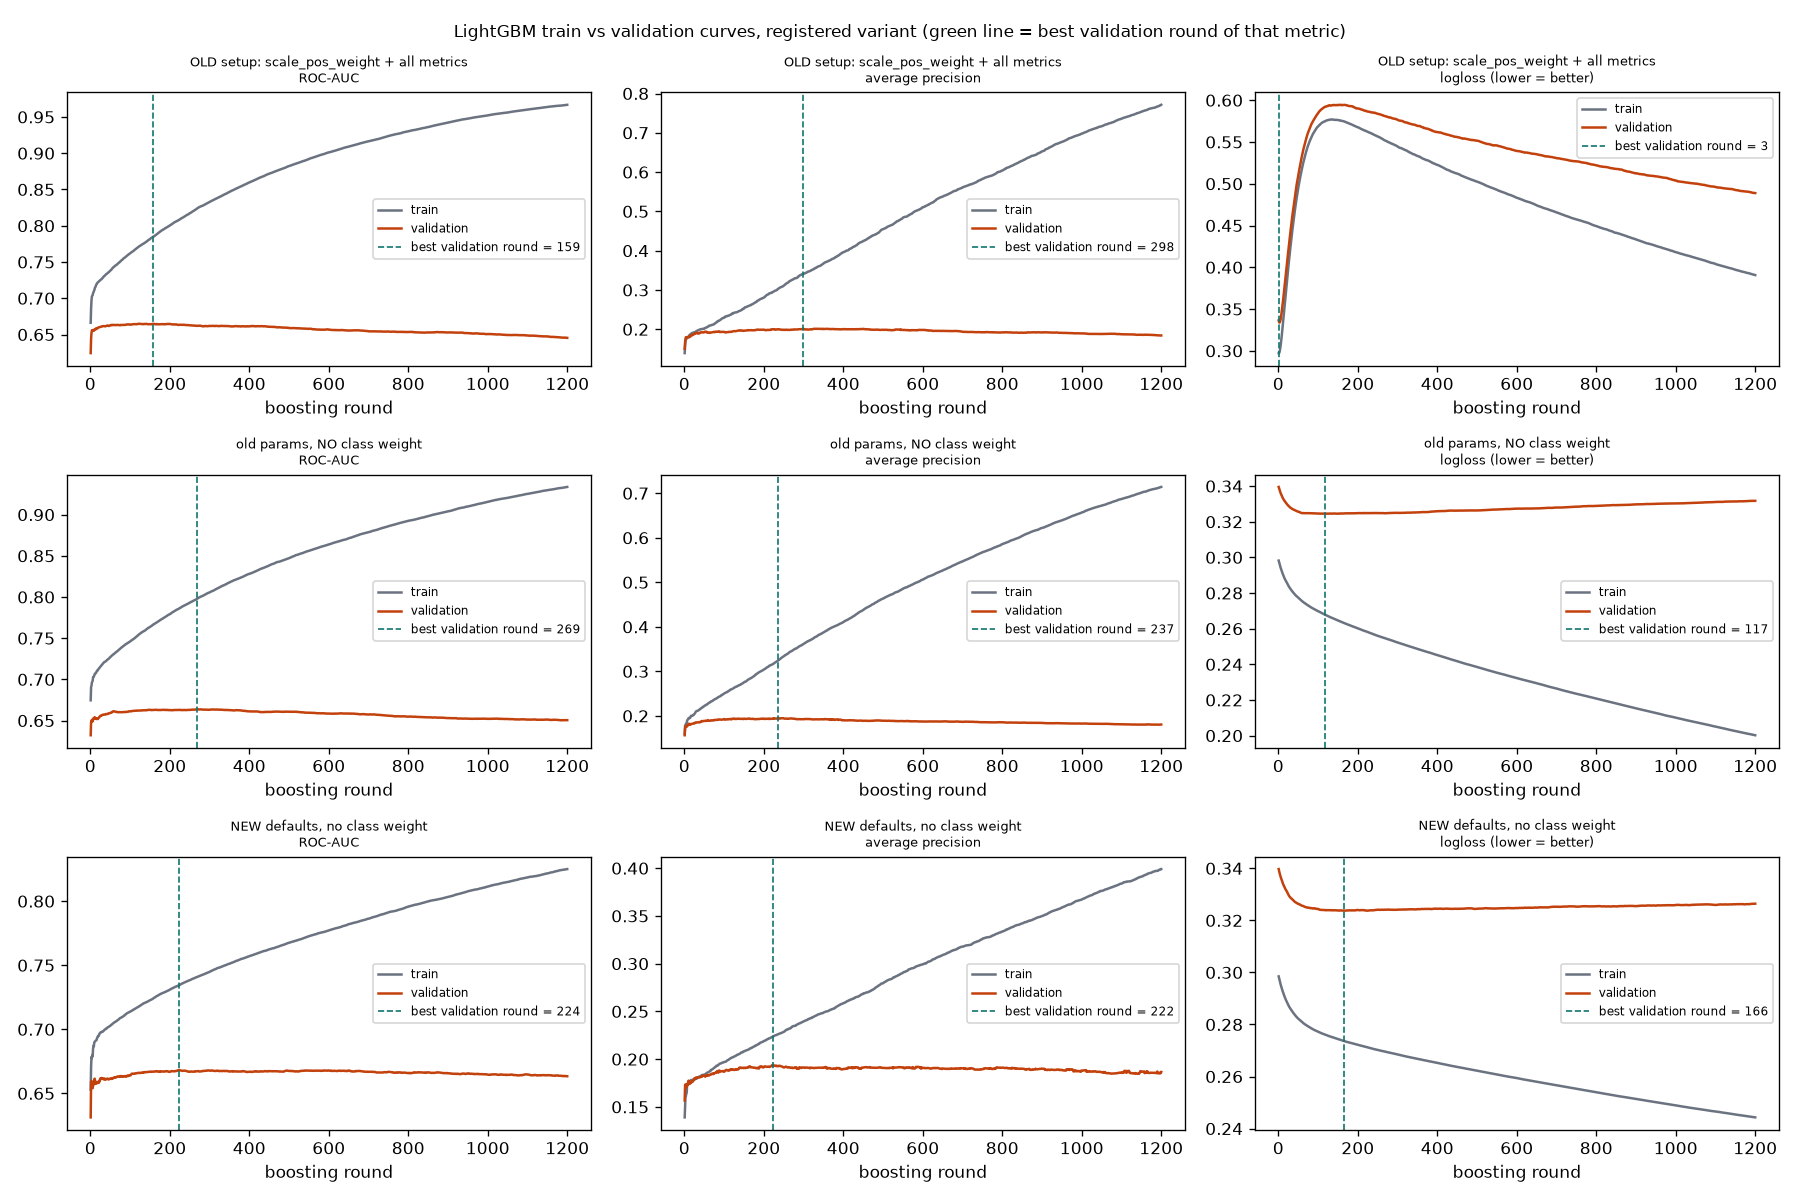

In [3]:
d = res["lightgbm"]["diagnostics"]["lightgbm_early_stop"]
print("LightGBM boosting rounds (registered variant)")
print(f"  nhanes_v003 (before): best_iteration_ = {d['nhanes_v003_reported_best_iteration']}")
print(f"  old setup replicated in notebook 04: best_iteration_ = {d['before_best_iteration']}, rounds trained = {d['before_rounds_trained']}, stopped by: {d['trigger_metric']}")
print(f"  nhanes_v003b (after): best_iteration_ = {d['after_final_best_iteration']}, rounds trained = {d['after_final_rounds_trained']}")
print("\nverdict on the suspected causes (computed in notebook 04):")
for k_, v_ in d["verdict"].items():
    print(("  TRUE : " if v_ else "  false: ") + k_)
print("\nbest_iteration_ of all three boosted models:")
print(pd.DataFrame(res["lightgbm"]["diagnostics"]["boosted_models_best_iteration"]).set_index("model").to_string())
display(Image(filename=str(nc.charts_dir() / "lightgbm_early_stop_curves.png")))

## 4. Class-imbalance comparison across models

Validation columns are cross-validated metrics of the calibrated probabilities on the validation calibration half; test columns are shown for information after the selection was frozen.

In [4]:
imb_rows = []
for k in ALL:
    imb = res[k]["variants"][PRIMARY]["imbalance"]
    tab = {r["strategy"]: r for r in imb["table"]}
    for s in nc.IMBALANCE_STRATEGIES:
        t = imb["test"][s]
        a = t["at_threshold"][nc.OP_ACCURACY]
        b = t["at_threshold"][nc.OP_BALANCED]
        imb_rows.append({"model": LABEL[k], "strategy": s, "selected": "<== selected" if s == imb["selected"] else "",
                         "val PR-AUC (calibrated, CV)": round(tab[s]["oof_pr_auc"], 4), "val Brier": round(tab[s]["oof_brier"], 4),
                         "val ROC-AUC": round(tab[s]["oof_roc_auc"], 4), "raw mean risk": round(tab[s]["mean_raw_risk"], 3),
                         "calibrated mean risk": round(tab[s]["mean_calibrated_risk"], 3),
                         "test ROC-AUC": round(t["roc_auc"], 4), "test PR-AUC": round(t["pr_auc"], 4),
                         "test acc @accuracy pt": None if a is None else round(a["accuracy"], 3),
                         "test sens @accuracy pt": None if a is None else round(a["sensitivity"], 3),
                         "test bal.acc @balanced pt": round(b["balanced_accuracy"], 3)})
imb_table = pd.DataFrame(imb_rows)
print("=== class-imbalance strategies x models (registered variant, default hyper-parameters). val = validation calibration half; test = display only ===")
print(imb_table.to_string(index=False))
nc.ensure(nc.metrics_dir() / "tables")
imb_table.to_csv(nc.metrics_dir() / "tables" / "cross_model_imbalance.csv", index=False)

imb_sum = []
for k in ALL:
    imb = res[k]["variants"][PRIMARY]["imbalance"]
    tab = pd.DataFrame(imb["table"]).set_index("strategy")
    sel = imb["selected"]
    gain = float(tab.loc[sel, "oof_pr_auc"] - tab.loc["none", "oof_pr_auc"])
    auc_range = float(tab["oof_roc_auc"].max() - tab["oof_roc_auc"].min())
    imb_sum.append({"model": LABEL[k], "selected": sel, "PR-AUC gain over none": round(gain, 4), "none within tie band": imb["selection"]["none_within_tie_band"],
                    "beat none beyond the tie band": gain > nc.STRATEGY_TIE_BAND, "ROC-AUC range over strategies": round(auc_range, 4)})
imb_summary = pd.DataFrame(imb_sum).set_index("model")
print("\n=== did any strategy beat 'none + calibration + threshold'? ===")
print(imb_summary.to_string())

=== class-imbalance strategies x models (registered variant, default hyper-parameters). val = validation calibration half; test = display only ===
                          model     strategy     selected  val PR-AUC (calibrated, CV)  val Brier  val ROC-AUC  raw mean risk  calibrated mean risk  test ROC-AUC  test PR-AUC  test acc @accuracy pt  test sens @accuracy pt  test bal.acc @balanced pt
                            EBM         none <== selected                       0.1910     0.0916       0.6625          0.087                 0.106        0.6789       0.1877                  0.728                   0.484                      0.628
                            EBM class_weight                                    0.1929     0.0916       0.6620          0.445                 0.106        0.6776       0.1874                  0.713                   0.505                      0.628
                            EBM  random_over                                    0.1447     0.0939       0.

## 5. Test results at both operating points

`accuracy` = max sensitivity s.t. validation accuracy >= 72%; `balanced` = max balanced accuracy. Both chosen on validation only. `majority baseline` is the accuracy of predicting no stone for everyone.

In [5]:
def ci(r, k, d=3):
    lo, hi = r[k + "_ci95"]
    return f"{r[k]:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"

rows = []
for k in ALL:
    v = res[k]["variants"][PRIMARY]
    t = v["test"]
    for pt in (nc.OP_ACCURACY, nc.OP_BALANCED):
        a = t["at_threshold"][pt]
        vt = v["thresholds"][pt]
        if a is None:
            rows.append({"model": LABEL[k], "operating point": pt, "threshold": "unreachable"})
            continue
        rows.append({"model": LABEL[k], "operating point": pt, "threshold": round(a["threshold"], 4), "val accuracy": round(vt["accuracy"], 3),
                     "test accuracy": ci(a, "accuracy"), "majority baseline": round(t["majority_baseline_accuracy"], 3),
                     "sensitivity": ci(a, "sensitivity"), "specificity": ci(a, "specificity"), "balanced acc.": ci(a, "balanced_accuracy"),
                     "pos-pred rate": round(a["positive_rate"], 3), "ROC-AUC": ci(t, "roc_auc"),
                     "accuracy > 70%?": "yes" if a["accuracy"] > nc.ACC_GOAL_TEST else f"NO ({a['accuracy']:.3f})"})
main_table = pd.DataFrame(rows).set_index(["model", "operating point"])
print("=== held-out test (2017-2018), registered variant", PRIMARY, "===")
print(main_table.to_string())
print("test cycle:", res["xgboost"]["variants"][PRIMARY]["test"]["evaluated_on"], "| n =", res["xgboost"]["variants"][PRIMARY]["test"]["n"],
      "| stone prevalence =", round(res["xgboost"]["variants"][PRIMARY]["test"]["prevalence"], 4))
reached = {k: (res[k]["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_ACCURACY] or {}).get("accuracy", 0) > nc.ACC_GOAL_TEST for k in ALL}
print("\ntest accuracy > 70% at the accuracy point:", {LABEL[k]: bool(x) for k, x in reached.items()})

=== held-out test (2017-2018), registered variant base_history_sensitive ===
                                                 threshold  val accuracy         test accuracy  majority baseline           sensitivity           specificity         balanced acc.  pos-pred rate               ROC-AUC accuracy > 70%?
model                           operating point                                                                                                                                                                                         
EBM                             accuracy            0.1314         0.720  0.716 [0.704, 0.728]                0.9  0.504 [0.461, 0.546]  0.739 [0.727, 0.751]  0.621 [0.600, 0.642]          0.285  0.674 [0.651, 0.697]             yes
                                balanced            0.1100         0.640  0.615 [0.603, 0.628]                0.9  0.630 [0.590, 0.669]  0.613 [0.600, 0.627]  0.622 [0.600, 0.642]          0.411  0.674 [0.651, 0.697]      NO

## 6. Feature-set ablation and leave-one-cycle-out stability

In [6]:
rows = []
for k in ALL:
    for v in cfg["variants"]:
        l = res[k]["variants"][v]["loco_cv"]
        r = res[k]["variants"][v]
        rows.append({"model": LABEL[k], "variant": v, "val AUC (cal half)": round(r["validation"]["roc_auc"], 4),
                     "LOCO AUC": f"{l['roc_auc_mean']:.4f} +/- {l['roc_auc_std']:.4f}", "LOCO AUC min-max": f"{l['roc_auc_min']:.3f}-{l['roc_auc_max']:.3f}",
                     "LOCO acc @accuracy pt": f"{l['acc_accuracy_mean']:.3f} +/- {l['acc_accuracy_std']:.3f}" if "acc_accuracy_mean" in l else "-",
                     "LOCO sens @accuracy pt": f"{l['sens_accuracy_mean']:.3f} +/- {l['sens_accuracy_std']:.3f}" if "sens_accuracy_mean" in l else "-",
                     "LOCO acc @balanced pt": f"{l['acc_balanced_mean']:.3f} +/- {l['acc_balanced_std']:.3f}", "LOCO sens @balanced pt": f"{l['sens_balanced_mean']:.3f} +/- {l['sens_balanced_std']:.3f}",
                     "test AUC": ci(r["test"], "roc_auc"), "test bal.acc @balanced": round(r["test"]["at_threshold"][nc.OP_BALANCED]["balanced_accuracy"], 3)})
ablation = pd.DataFrame(rows)
print("=== feature-set ablation and stability across survey cycles (LOCO = leave-one-cycle-out, mean +/- sd over 5 cycles) ===")
print(ablation.set_index(["model", "variant"]).to_string())

=== feature-set ablation and stability across survey cycles (LOCO = leave-one-cycle-out, mean +/- sd over 5 cycles) ===
                                                        val AUC (cal half)           LOCO AUC LOCO AUC min-max LOCO acc @accuracy pt LOCO sens @accuracy pt LOCO acc @balanced pt LOCO sens @balanced pt              test AUC  test bal.acc @balanced
model                           variant                                                                                                                                                                                                               
EBM                             base                                0.6497  0.6545 +/- 0.0110      0.640-0.670       0.723 +/- 0.004        0.457 +/- 0.017       0.582 +/- 0.003        0.648 +/- 0.012  0.650 [0.626, 0.673]                   0.606
                                base_history                        0.6629  0.6611 +/- 0.0102      0.646-0.671       0.763 +/- 0.004       

## 7. Plots (from the stored test predictions)

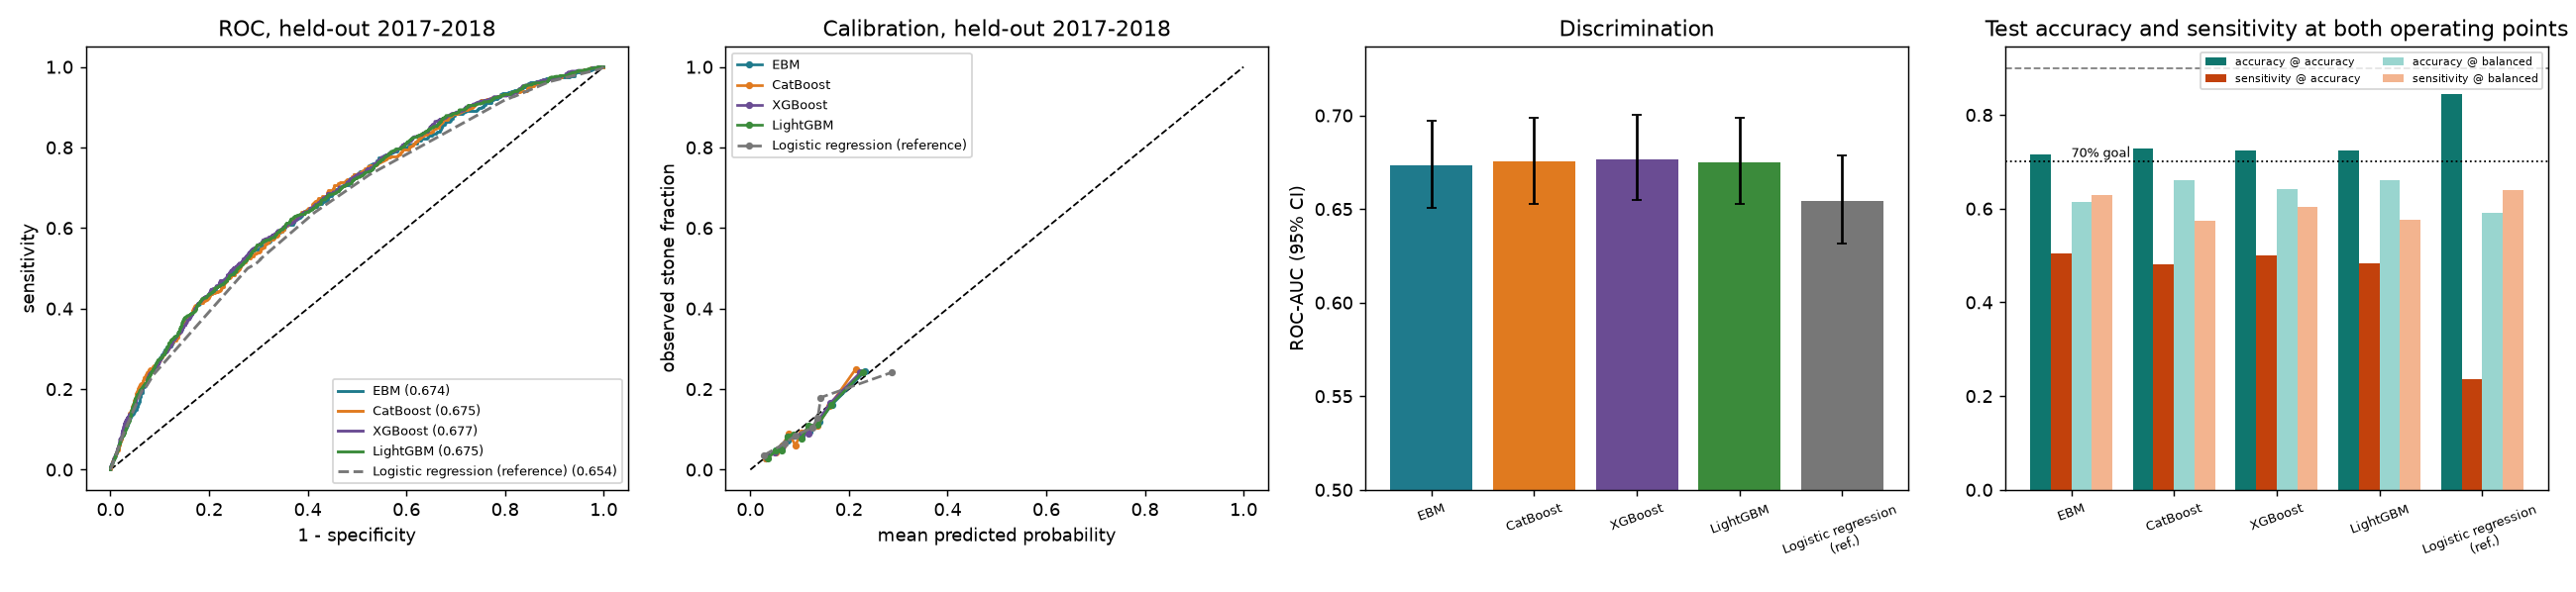

In [7]:
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

pred = {k: np.load(nc.predictions_dir() / f"{res[k]['model_name']}__{PRIMARY}__test.npz") for k in ALL}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
for k in ALL:
    fpr, tpr, _ = roc_curve(pred[k]["y"], pred[k]["p"])
    ax[0].plot(fpr, tpr, color=COLOR[k], lw=1.6, ls="--" if k == "logreg" else "-", label=f"{LABEL[k]} ({res[k]['variants'][PRIMARY]['test']['roc_auc']:.3f})")
ax[0].set_xlabel("1 - specificity"); ax[0].set_ylabel("sensitivity"); ax[0].set_title("ROC, held-out 2017-2018"); ax[0].legend(fontsize=7)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
for k in ALL:
    frac, mp = calibration_curve(pred[k]["y"], pred[k]["p"], n_bins=10, strategy="quantile")
    ax[1].plot(mp, frac, "o-", ms=3, color=COLOR[k], ls="--" if k == "logreg" else "-", label=LABEL[k])
ax[1].set_xlabel("mean predicted probability"); ax[1].set_ylabel("observed stone fraction"); ax[1].set_title("Calibration, held-out 2017-2018"); ax[1].legend(fontsize=7)
names = [LABEL[k] for k in ALL]
est = [res[k]["variants"][PRIMARY]["test"]["roc_auc"] for k in ALL]
err = [[e - res[k]["variants"][PRIMARY]["test"]["roc_auc_ci95"][0] for k, e in zip(ALL, est)], [res[k]["variants"][PRIMARY]["test"]["roc_auc_ci95"][1] - e for k, e in zip(ALL, est)]]
ax[2].bar(range(len(names)), est, yerr=err, color=[COLOR[k] for k in ALL], capsize=3)
ax[2].set_xticks(range(len(names))); ax[2].set_xticklabels([n.replace(" (reference)", "\n(ref.)") for n in names], rotation=20, fontsize=7)
ax[2].set_ylim(0.5, max(est) + 0.06); ax[2].set_ylabel("ROC-AUC (95% CI)"); ax[2].set_title("Discrimination")
w = 0.2
xs = np.arange(len(ALL))
for i, (pt, metric, col) in enumerate([(nc.OP_ACCURACY, "accuracy", "#0f766e"), (nc.OP_ACCURACY, "sensitivity", "#c2410c"),
                                       (nc.OP_BALANCED, "accuracy", "#99d5cf"), (nc.OP_BALANCED, "sensitivity", "#f3b48f")]):
    vals = [(res[k]["variants"][PRIMARY]["test"]["at_threshold"][pt] or {}).get(metric, 0) for k in ALL]
    ax[3].bar(xs + (i - 1.5) * w, vals, w, color=col, label=f"{metric} @ {pt}")
ax[3].axhline(nc.ACC_GOAL_TEST, color="k", ls=":", lw=1); ax[3].text(0, nc.ACC_GOAL_TEST + 0.01, "70% goal", fontsize=7)
ax[3].axhline(res["xgboost"]["variants"][PRIMARY]["test"]["majority_baseline_accuracy"], color="gray", ls="--", lw=1)
ax[3].set_xticks(xs); ax[3].set_xticklabels([LABEL[k].replace(" (reference)", "\n(ref.)") for k in ALL], rotation=20, fontsize=7)
ax[3].set_title("Test accuracy and sensitivity at both operating points"); ax[3].legend(fontsize=6, ncol=2)
fig.tight_layout()
nc.ensure(nc.charts_dir())
fig.savefig(nc.charts_dir() / "comparison_roc_calibration_auc.png", dpi=130)
plt.close(fig)
display(Image(filename=str(nc.charts_dir() / "comparison_roc_calibration_auc.png")))

## 8. Register the four models (status `pending_review`, not deployed)

The registered variant's frozen bundle (preprocessor + estimator + calibrator + both thresholds) is wrapped in the matching `BaseRiskModel` wrapper and added to the registry as `<model>_nhanes_v003b`. `active_model_version` and all earlier entries are unchanged.

In [8]:
import shutil
from ml.risk_models.registry import ModelRegistry
from ml.risk_models.wrappers import XGBoostNhanesRiskModel, CatBoostRiskModel, LightGBMRiskModel, EBMRiskModel

WRAPPER = {"xgboost": XGBoostNhanesRiskModel, "catboost": CatBoostRiskModel, "lightgbm": LightGBMRiskModel, "ebm": EBMRiskModel}
real_manifest = nc.PROJECT_ROOT / "ml" / "models" / "registry_manifest.json"
if nc.is_dry_run():
    nc.ensure(nc.manifest_path().parent)
    shutil.copyfile(real_manifest, nc.manifest_path())
before = nc.load_json(nc.manifest_path())
registry = ModelRegistry(versions_dir=nc.versions_dir(), manifest_path=nc.manifest_path())
registered = {}
for k in MODELS:
    r = res[k]
    v = r["variants"][PRIMARY]
    bundle = joblib.load(v["bundle_path"])
    assert nc.file_sha256(Path(v["bundle_path"])) == v["bundle_sha256"], "bundle changed after the notebook froze it"
    fields = nc.registry_entry_fields(r, PRIMARY)
    t = fields["test_metrics"]["at_accuracy_threshold"]
    tag = f"{k}_{nc.RUN_TAG}"
    model = WRAPPER[k](bundle=bundle, version_tag=tag, threshold=bundle.threshold, feature_names=bundle.input_features)
    registry.register_model(
        model, set_active=False, extra_entry_fields=fields,
        metadata={"trained_at": r["trained_at"], "metrics": {
            "test_cycle": fields["test_metrics"]["test_cycle"], "roc_auc": fields["test_metrics"]["roc_auc"], "operating_point": nc.OP_ACCURACY,
            "accuracy": t["accuracy"], "balanced_accuracy": t["balanced_accuracy"], "sensitivity": t["sensitivity"], "specificity": t["specificity"],
            "majority_baseline_accuracy": fields["test_metrics"]["majority_baseline_accuracy"]}})
    registered[k] = tag

# make artifact paths machine independent (the registry falls back to the repo-relative path)
manifest = nc.load_json(nc.manifest_path())
for tag in registered.values():
    manifest["models"][tag]["absolute_artifact_path"] = manifest["models"][tag]["artifact_path"]
with open(nc.manifest_path(), "w", encoding="utf-8", newline="\n") as f:     # same formatting as ModelRegistry (indent=4), LF line endings
    json.dump(nc.jsonable(manifest), f, indent=4)
assert manifest["active_model_version"] == before["active_model_version"] == "logistic_regression_v001"
assert not any(manifest["models"][t]["is_deployed"] for t in registered.values())
assert all(old in manifest["models"] for old in before["models"])   # earlier entries (v001 / v002 / nhanes_v003) are still there
for t in before["models"]:
    if t not in registered.values():
        assert manifest["models"][t] == before["models"][t], f"existing entry {t} changed"
display(pd.DataFrame({t: {"family": manifest["models"][t]["model_family"], "status": manifest["models"][t]["status"],
                          "deployed": manifest["models"][t]["is_deployed"], "default point": manifest["models"][t]["default_operating_point"],
                          "accuracy-pt thr": round(manifest["models"][t]["thresholds"]["accuracy"], 4),
                          "balanced-pt thr": round(manifest["models"][t]["thresholds"]["balanced"], 4),
                          "strategy": manifest["models"][t]["imbalance_strategy"], "variant": manifest["models"][t]["variant"],
                          "device": manifest["models"][t]["device"]["actual"]} for t in registered.values()}).T)
print("active model unchanged:", manifest["active_model_version"], "| earlier nhanes_v003 entries kept:", sorted(t for t in manifest["models"] if t.endswith("_nhanes_v003")))

,family,status,deployed,default point,accuracy-pt thr,balanced-pt thr,strategy,variant,device
ebm_nhanes_v003b,ebm,pending_review,False,accuracy,0.1314,0.11,none,base_history_sensitive,cpu
catboost_nhanes_v003b,catboost,pending_review,False,accuracy,0.1332,0.119,class_weight,base_history_sensitive,GPU
xgboost_nhanes_v003b,xgboost,pending_review,False,accuracy,0.1316,0.1138,none,base_history_sensitive,cuda:0
lightgbm_nhanes_v003b,lightgbm,pending_review,False,accuracy,0.1316,0.1171,none,base_history_sensitive,cpu


active model unchanged: logistic_regression_v001 | earlier nhanes_v003 entries kept: ['catboost_nhanes_v003', 'ebm_nhanes_v003', 'lightgbm_nhanes_v003', 'xgboost_nhanes_v003']


### Registry round trip

Load each registered model back through the registry, check it reproduces the saved bundle's scores, can explain a row, and that the registry's operating-point values equal the metrics JSON.

In [9]:
reg2 = ModelRegistry(versions_dir=nc.versions_dir(), manifest_path=nc.manifest_path())
val_rows = nc.load_frozen_splits(include_test=False)["validation"].head(25)
for k, tag in registered.items():
    m = reg2.get_model(tag)
    p_reg = m.predict_proba(val_rows)[:, 1]
    p_ref = joblib.load(res[k]["variants"][PRIMARY]["bundle_path"]).predict_proba(val_rows)
    np.testing.assert_allclose(p_reg, p_ref, atol=1e-6)
    ex = m.explain(val_rows.iloc[[0]])
    assert set(ex) >= {"top_features", "feature_contributions", "feature_directions", "summary"}
    entry = next(e for e in reg2.list_models() if e["version_tag"] == tag)
    # the registry values must equal the metrics JSON values (the app reads the registry)
    jt = res[k]["variants"][PRIMARY]["test"]["at_threshold"]
    for pt in nc.OPERATING_POINTS:
        assert abs(entry["operating_points"][pt]["test"]["accuracy"] - jt[pt]["accuracy"]) < 1e-12
        assert abs(entry["operating_points"][pt]["test"]["sensitivity"] - jt[pt]["sensitivity"]) < 1e-12
        assert abs(entry["thresholds"][pt] - jt[pt]["threshold"]) < 1e-12
    print(f"{tag}: family={m.model_family} default threshold={m.threshold:.3f} top factors={ex['top_features'][:3]} | registry == metrics JSON: OK")

ebm_nhanes_v003b: family=ebm default threshold=0.131 top factors=['RIDRETH1', 'RIDAGEYR', 'DIQ010'] | registry == metrics JSON: OK

catboost_nhanes_v003b: family=catboost default threshold=0.133 top factors=['DIQ010', 'RIDAGEYR', 'URXUMA'] | registry == metrics JSON: OK
xgboost_nhanes_v003b: family=xgboost default threshold=0.132 top factors=['RIDAGEYR', 'DIQ010', 'URXUMA'] | registry == metrics JSON: OK
lightgbm_nhanes_v003b: family=lightgbm default threshold=0.132 top factors=['RIDAGEYR', 'DIQ010', 'RIDRETH1'] | registry == metrics JSON: OK


## 9. Write the report

In [10]:
def f3(x): return f"{x:.3f}"
def pct(x): return f"{100 * x:.1f}%"
t_ref = res["xgboost"]["variants"][PRIMARY]["test"]
prev, base_acc = t_ref["prevalence"], t_ref["majority_baseline_accuracy"]
auc_rng = (min(res[k]["variants"][PRIMARY]["test"]["roc_auc"] for k in MODELS), max(res[k]["variants"][PRIMARY]["test"]["roc_auc"] for k in MODELS))
bal_rng = (min(res[k]["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_BALANCED]["balanced_accuracy"] for k in MODELS),
           max(res[k]["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_BALANCED]["balanced_accuracy"] for k in MODELS))
best = max(MODELS, key=lambda k: res[k]["variants"][PRIMARY]["test"]["roc_auc"])
ranges = {k: res[k]["variants"][PRIMARY]["test"]["roc_auc_ci95"] for k in MODELS}
all_overlap = all(ranges[a][0] <= ranges[b][1] and ranges[b][0] <= ranges[a][1] for a in MODELS for b in MODELS)
closeness = ("The four models are statistically close: all pairwise 95% confidence intervals overlap." if all_overlap
             else "At least one pair of models has non-overlapping 95% confidence intervals for ROC-AUC.")

def md_table(df):
    d = df.reset_index()
    out = ["| " + " | ".join(map(str, d.columns)) + " |", "|" + "|".join("---" for _ in d.columns) + "|"]
    out += ["| " + " | ".join(str(x) for x in row) + " |" for row in d.values.tolist()]
    return "\n".join(out)

acc_lines, sens_acc = [], []
for k in MODELS:
    a = res[k]["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_ACCURACY]
    b = res[k]["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_BALANCED]
    if a is None:
        acc_lines.append(f"- {LABEL[k]}: no cut-off reached {pct(nc.ACC_TARGET_VALIDATION)} accuracy on the validation calibration half.")
        continue
    ok = a["accuracy"] > nc.ACC_GOAL_TEST
    sens_acc.append(a["sensitivity"])
    acc_lines.append(f"- {LABEL[k]}: accuracy point (cut-off {a['threshold']:.3f}) test accuracy **{pct(a['accuracy'])}** ({'above' if ok else 'BELOW'} 70%), sensitivity {pct(a['sensitivity'])}, "
                     f"specificity {pct(a['specificity'])}, balanced accuracy {pct(a['balanced_accuracy'])}, flags {pct(a['positive_rate'])} of people; "
                     f"balanced point (cut-off {b['threshold']:.3f}) accuracy {pct(b['accuracy'])}, sensitivity {pct(b['sensitivity'])}, specificity {pct(b['specificity'])}, balanced accuracy {pct(b['balanced_accuracy'])}.")
n_reached = sum(1 for k in MODELS if reached[k])
d = res["lightgbm"]["diagnostics"]["lightgbm_early_stop"]
cause_lines = [f"- {'**TRUE**' if v_ else 'false'}: {k_}" for k_, v_ in d["verdict"].items()]
imb_lines = []
for k in MODELS:
    imb = res[k]["variants"][PRIMARY]["imbalance"]
    row = imb_summary.loc[LABEL[k]]
    imb_lines.append(f"- {LABEL[k]}: selected **{imb['selected']}** (post-calibration PR-AUC gain over 'none' {row['PR-AUC gain over none']:+.4f}; "
                     f"'none' within the {nc.STRATEGY_TIE_BAND} tie band: {row['none within tie band']}; ROC-AUC spread across the five strategies {row['ROC-AUC range over strategies']:.4f}).")
n_beat = int(imb_summary.loc[[LABEL[k] for k in MODELS], "beat none beyond the tie band"].sum())
mx = md_table(main_table.reset_index().set_index("model"))
boost_md = md_table(pd.DataFrame(res["lightgbm"]["diagnostics"]["boosted_models_best_iteration"]).set_index("model"))
prov_md = md_table(prov_table[["notebook", "executed_at (UTC)", "device", "training s", "notebook s"]])
imb_md = md_table(imb_table.set_index("model"))
loco_md = md_table(ablation[ablation["variant"] == PRIMARY].set_index("model"))
avail = pd.DataFrame(data_sum["history_availability"])
avail["shown"] = np.where(avail["present"], avail["percent_missing"].astype(str), "absent")
avail_md = md_table(avail.pivot(index="variable", columns="cycle", values="shown"))
leak = pd.DataFrame(data_sum["leakage_audit"]).head(8)
imp_lines = [f"- {LABEL[k]}: " + ", ".join(f"{r['feature']} ({r['mean_abs_contribution']:.2f})" for r in res[k]["variants"][PRIMARY]["importance_validation"][:6]) for k in MODELS]
rates = data_sum["split_manifest"]["positive_rate"]

report = f"""# NHANES kidney-stone risk models, `nhanes_v003b`: four-model comparison

*Generated {time.strftime('%Y-%m-%d %H:%M:%SZ', time.gmtime())} by `05_compare_and_register.ipynb` from the saved outputs of notebooks 00-04b.{' **DRY RUN: the validation cycle stood in for the test cycle; do not quote these numbers.**' if nc.is_dry_run() else ''}*

Status: all four registered models are **`pending_review`, not deployed**. The active model is still `logistic_regression_v001`; the earlier `*_nhanes_v003` entries are kept. These are research-prototype models trained on a US survey with a **self-reported** outcome; they are not diagnostic tools.

## 1. Summary

- Target: self-reported kidney stone (`KIQ026`), {pct(prev)} positive in the test cycle. Predicting "no stone" for everyone gives **{pct(base_acc)} accuracy**.
- Discrimination is unchanged in kind: test ROC-AUC of the four models is {f3(auc_rng[0])} to {f3(auc_rng[1])} (best: {LABEL[best]}, {ci(res[best]['variants'][PRIMARY]['test'], 'roc_auc')}) and balanced accuracy at the balanced point is {pct(bal_rng[0])} to {pct(bal_rng[1])}. {closeness} This is a **small signal**: useful for ranking, weak for individual decisions. ROC-AUC and balanced accuracy are not expected to exceed 70% and were not forced.
- **Accuracy above 70% is obtained at the cost of sensitivity.** {n_reached} of 4 models exceed 70% test accuracy at the accuracy-focused operating point, at a sensitivity of {pct(min(sens_acc)) if sens_acc else 'n/a'} to {pct(max(sens_acc)) if sens_acc else 'n/a'}; the majority baseline is {pct(base_acc)}, so none of these accuracies is evidence of skill by itself.
- LightGBM no longer stops after a handful of rounds: best_iteration_ {d['nhanes_v003_reported_best_iteration']} (nhanes_v003) -> {d['after_final_best_iteration']} (nhanes_v003b).
- Registered feature set: `{PRIMARY}` ({len(cfg['variants'][PRIMARY])} inputs). History features used: {', '.join(cfg['history_features_used'])}. Race and income {'ARE' if 'RIDRETH1' in cfg['variants'][PRIMARY] else 'are NOT'} inputs of the registered models.

## 2. Every number comes from an executed notebook

{prov_md}

All five metrics files carry the same frozen-split hash (`{SPLIT_HASH[:16]}`), which this notebook verified before reading anything else. The held-out test cycle is scored once per frozen model, inside the model notebooks, through `final_test_evaluation`.

## 3. LightGBM early stop: diagnosis and fix

Before: `best_iteration_` = {d['nhanes_v003_reported_best_iteration']} in nhanes_v003; replicated in notebook 04 as {d['before_best_iteration']} (rounds trained {d['before_rounds_trained']}), stopped by `{d['trigger_metric']}`. After: `best_iteration_` = {d['after_final_best_iteration']} (rounds trained {d['after_final_rounds_trained']}).

Verdict on the suspected causes (evidence in the notebook-04 tables and `ml/outputs/charts/nhanes_v003/lightgbm_early_stop_curves.png`):

{chr(10).join(cause_lines)}

Fix: early-stop on validation AUC only (`first_metric_only=True`, patience {d['stopping_rounds_new']}), slower learning rate, shallow trees with large leaves and strong regularisation, a single imbalance strategy chosen in section 4 of the notebook (no stacking of weights and resampling), and the 2015-2016 validation cycle split by `SEQN` into an early-stopping half and a calibration/threshold half. Best iteration of the three boosted models (registered variant):

{boost_md}

## 4. Class-imbalance handling

Five strategies on the same frozen split, resampling on training rows only (imblearn Pipeline; SMOTENC with the binary/categorical columns declared), each calibrated on the real-prevalence validation half, selected on validation by post-calibration PR-AUC (ties within {nc.STRATEGY_TIE_BAND} resolved by Brier, then simplicity):

{chr(10).join(imb_lines)}

**{n_beat} of 4 boosted/EBM models gained more than the tie band in PR-AUC over "none + calibration + threshold".** The validation calibration half holds only {res['lightgbm']['validation_halves']['calibration_positives']} positives, so PR-AUC differences of about {nc.STRATEGY_TIE_BAND} or less between strategies are within sampling noise; the selection is a pre-declared tie-break, not evidence that one strategy is better. Balancing inflates raw probabilities (see "raw mean risk" vs "calibrated mean risk" below) and mostly moves the decision threshold; calibration restores the real prevalence, so the risk percentages shown in the app are calibrated.

{imb_md}

## 5. Operating points and held-out test results (registered variant `{PRIMARY}`)

`accuracy` point = maximise sensitivity subject to validation accuracy >= {pct(nc.ACC_TARGET_VALIDATION)}; `balanced` point = maximise balanced accuracy. Both thresholds come from the validation calibration half only. 95% CIs from 1,000 bootstrap resamples of the test cycle; they describe performance on held-out 2017-2018 NHANES data, not the accuracy for any single patient.

{chr(10).join(acc_lines)}

{mx}

## 6. Cohort and raw-data checks

{md_table(pd.DataFrame(data_sum['cohort_check']).set_index('cycle'))}

The cohort CSV matches the raw `KIQ_U` files in every cycle. The v2 cohort adds the history features by a one-to-one left merge on `SEQN`, with row and label counts asserted unchanged, and drops `KIQ029`.

History-feature availability (percent missing after decoding refused / don't-know; "absent" = not collected):

{avail_md}

Decision: {'; '.join(f"`{v}` {'USED' if dd['usable'] else 'EXCLUDED'} ({dd['reason']})" for v, dd in data_sum['history_decisions'].items())}.

Leakage audit (single-feature ROC-AUC on the training cycles, top 8 of {len(data_sum['leakage_audit'])}; flag threshold 0.85; none flagged):

{md_table(leak.set_index('feature'))}

Never used as features: `SEQN, CYCLE, target_stone, KIQ026, KIQ029, WTMEC2YR, WTINT2YR, SDMVPSU, SDMVSTRA`.

## 7. Splits (by survey cycle, frozen, hash `{SPLIT_HASH[:16]}`)

{md_table(pd.DataFrame(data_sum['split_summary']).set_index('split'))}

Stone prevalence is {pct(rates['train'])} (train), {pct(rates['validation'])} (validation) and {pct(rates['test'])} (test); differences are reported, not adjusted. Imputers and scalers are fit on the training cycles only. Resampling (where selected) touches training rows only; validation and test are never resampled.

## 8. Feature-set ablation and stability across survey cycles

{md_table(ablation.set_index(['model', 'variant']))}

LOCO accuracy / sensitivity place the cut-off by the fraction of people the validation-chosen operating point flags (fold models are uncalibrated); no held-out label is used.

## 9. What the models use (mean absolute contribution on validation, log-odds)

{chr(10).join(imp_lines)}

Contributions describe what the model relies on; they do not establish causation.

## 10. Registry

Registered (pending_review, not deployed): {', '.join(f'`{t}`' for t in registered.values())}, default operating point `accuracy`, both operating points stored with validation and test metrics. Artifacts: `ml/models/versions/<tag>.pkl`; form definition: `ml/artifacts/nhanes_v003/feature_spec.json`; metrics: `ml/outputs/metrics/nhanes_v003/`. The previous run's metrics and report are kept in `ml/outputs/metrics/nhanes_v003/_prev_v003/`.

## 11. Limitations and honesty notes

- The label is **self-reported** ("Have you ever had a kidney stone?"), not imaging- or lab-confirmed, and "ever" is not "currently".
- US adults aged 20-80 in NHANES 2007-2018; survey weights were not used for training, so results are not nationally representative estimates and may not transfer elsewhere.
- The signal is small (ROC-AUC {f3(auc_rng[0])}-{f3(auc_rng[1])}); the four models are close and their confidence intervals overlap.
- **The 2017-2018 test cycle had already been scored once by `nhanes_v003`** before this revision was designed. `nhanes_v003b` made no choice (threshold, strategy, hyper-parameters, features) using test data, but the decision to revise the operating point and the LightGBM settings was informed by seeing the earlier results, so the test numbers are a second look, not a first one.
- Accuracy above 70% at the accuracy-focused point means the model flags fewer people as High risk and misses more true cases; it must not be read as "70% of stone cases are found".
- Predictors are cross-sectional and measured at the same visit as the self-reported outcome; they are associations, not proven risk factors. Not validated prospectively and not approved for clinical use.
"""
rep_path = nc.ensure(nc.reports_dir()) / "nhanes_v003_report.md"
rep_path.write_text(report, encoding="utf-8")
print("report written:", nc.rel(rep_path), f"({len(report)} chars)")
print(f"PROVENANCE notebook={NOTEBOOK_FILE} executed_at={time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())} split_hash={SPLIT_HASH}")

report written: ml/outputs/reports/nhanes_v003_report.md (21082 chars)
PROVENANCE notebook=05_compare_and_register.ipynb executed_at=2026-10-15T08:47:39Z split_hash=a2c3bdb15ffb9f3b943ec517e878cd8c59a92c444acd15ef7e35446fd0fcc7e7
